In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from matplotlib import ticker

from mol_faith.notebooks.results_analysis.shared import load_raw_data
from mol_faith.notebooks.results_analysis.shared import process_fidelity_df
from mol_faith.notebooks.results_analysis.shared import map_explanation_method_names
from mol_faith.notebooks.results_analysis.shared import get_target_colors

In [2]:
logp_target_base_path = '../../../results/logp_target'
logp_raw_data_df = load_raw_data(base_dir=logp_target_base_path, target_name='logp')

Found XAI methods: ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling']
Excluded methods: []

Processing GCN...
  gnn_explainer: 6900 rows
  grad_cam: 6900 rows
  graph_mask: 6900 rows
  guided_grad_cam: 6782 rows
  integrated_gradients: 6900 rows
  kernel_shap: 6900 rows
  lime: 6900 rows
  random_explanation: 6900 rows
  shap_sampling: 6900 rows
  GCN total: 61982 rows

Processing Transformer...
  integrated_gradients: 6900 rows
  kernel_shap: 6900 rows
  lime: 6900 rows
  random_explanation: 6900 rows
  shap_sampling: 6900 rows
  Transformer total: 34500 rows

Processing CNN...
  grad_cam: 6900 rows
  guided_grad_cam: 6900 rows
  integrated_gradients: 6900 rows
  kernel_shap: 6900 rows
  lime: 6900 rows
  random_explanation: 6900 rows
  shap_sampling: 6900 rows
  CNN total: 48300 rows

Processing GIN...
  gnn_explainer: 6900 rows
  graph_mask: 6900 rows
  integrated_gradients: 6900 rows
 

In [3]:
logp_raw_processed_data_df = process_fidelity_df(logp_raw_data_df)

Total samples: 206882

Regime distribution:
regime
faithful      143196
unfaithful     63686
Name: count, dtype: int64

Faithfulness statistics by regime:
           normalized_fid                                      fid_plus  \
                    count    mean  median     std     min  max     mean   
regime                                                                    
faithful           143196  0.4732  0.5961  0.5317 -0.9999  1.0   0.2199   
unfaithful          63686 -0.5930 -0.5961  0.3692 -1.0000 -0.0  -0.1131   

                            
               min     max  
regime                      
faithful    0.0000  4.3254  
unfaithful -2.2967 -0.0000  

Overall faithfulness score range: [-1.000, 1.000]


In [4]:
def create_grouped_boxplot(target_dataframes,
                           value_col,
                           group_col,
                           figsize=(7, 3),
                           save_plot=False,
                           output_dir=None,
                           linewidth=2,
                           box_width=0.18,
                           gap=0.1,
                           font_scale=1,
                           show_minmax=True,
                           minmax_marker='D',
                           minmax_size=30,
                           plot_linewidth=0.5,
                           labelsize=9,
                           tick_label_size=8,
                           tick_width=0.5,
                           tick_length=2,
                           reference_fig=None):
    if not target_dataframes:
        print("No data provided!")
        return None

    combined_data = []
    for target, df in target_dataframes.items():
        if df.empty:
            continue
        df_copy = df.copy()
        df_copy['target'] = target
        df_copy = map_explanation_method_names(df_copy)
        combined_data.append(df_copy)

    if not combined_data:
        print("No valid data found!")
        return None

    full_df = pd.concat(combined_data, ignore_index=True)

    if group_col == 'model':
        label_order = ['Transformer', 'CNN', 'GAT', 'GCN', 'GIN']
    else:
        label_order = ['IG', 'SHAP', 'KernelSHAP', 'LIME', 'GradCAM', 'Guided GradCAM', 'GNNExplainer', 'GraphMask']

    targets = list(target_dataframes.keys())

    print(f"Creating seaborn grouped boxplot with {len(label_order)} groups and {len(targets)} targets per group")

    fig, ax = plt.subplots(figsize=figsize)

    sns.set_style("whitegrid", {"axes.grid": False, 'xtick.bottom': True, 'ytick.left': True, 'font': 'Arial'})
    sns.set_context("paper")

    target_colors = get_target_colors()

    box_plot = sns.boxplot(
        data=full_df,
        x=group_col,
        y=value_col,
        # hue='target',
        # hue_order=['Conjugated System', 'Benzene', 'Hbond Donor'],
        # order=label_order,
        linewidth=linewidth,
        ax=ax,
        # palette=target_colors,
        width=box_width,
        showfliers=False,
        gap=gap,
        dodge=True,
        legend=False
    )

    ax.axhline(y=0, color='grey', linestyle='-', linewidth=plot_linewidth, alpha=0.5, zorder=1)

    x_label = 'Model' if group_col == 'model' else 'xAI Method'
    ax.set_xlabel(x_label, fontsize=labelsize)
    ax.set_ylabel('Fid+', fontsize=labelsize)
    ax.tick_params(axis='y', labelsize=tick_label_size, width=tick_width, length=tick_length)
    ax.tick_params(axis='x', labelsize=tick_label_size, width=tick_width, length=tick_length, labelrotation=45)
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))

    # if group_col != 'model':
    #     if reference_fig is not None:
    #         ref_ax = reference_fig.get_axes()[0]
    #         ref_yticks = ref_ax.get_yticks()
    #         ref_ylim = ref_ax.get_ylim()
    #         visible_ticks = [tick for tick in ref_yticks if ref_ylim[0] <= tick <= ref_ylim[1]]
    #         ax.set_yticks(visible_ticks)
    #         ax.set_ylim(ref_ylim) 
    #     else:
    #         ax.set_yticks([0.12, 0.08, 0.05, 0.02, 0.00, -0.02, -0.05, -0.08])

    for spine in ax.spines.values():
        spine.set_linewidth(plot_linewidth)

    handles, labels = ax.get_legend_handles_labels()

    plt.tight_layout()

    if group_col == 'model':
        saving_prefix = 'model'
    else:
        saving_prefix = 'method'

    if save_plot and output_dir:
        Path(output_dir).mkdir(parents=True, exist_ok=True)
        plt.savefig(Path(output_dir) / f'{saving_prefix}_grouped_boxplot.png', dpi=450, bbox_inches='tight')
        plt.savefig(Path(output_dir) / f'{saving_prefix}_grouped_boxplot.svg', format='svg', dpi=450,
                    bbox_inches='tight')

    plt.show()
    return fig

Creating seaborn grouped boxplot with 8 groups and 1 targets per group


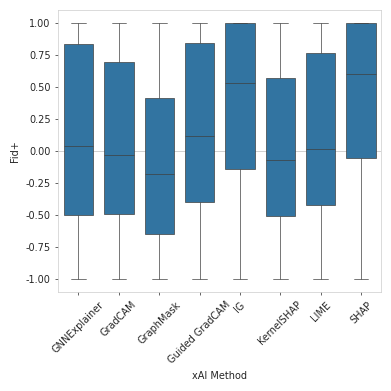

In [9]:
target_data = {
    'logp': logp_raw_processed_data_df,
}

model_fig = create_grouped_boxplot(target_data,
                       output_dir='/home/marcelhiltscher/Documents/image_sync/results/logp_target',
                       value_col='normalized_fid',
                       group_col='explanation_method',
                       figsize=(4, 4),
                       save_plot=True,
                       box_width=0.8,
                       gap=0.09,
                       linewidth=0.5,
                       plot_linewidth=0.5,
                       show_minmax=False,
                       labelsize=7,
                       tick_label_size=7,
                       minmax_size=12)

Creating seaborn grouped boxplot with 5 groups and 1 targets per group


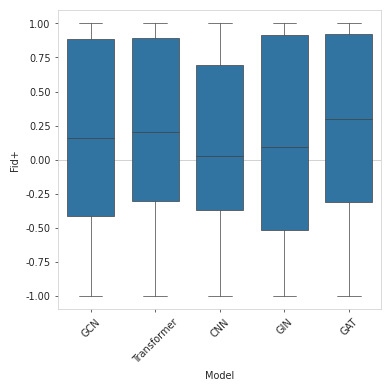

In [10]:
target_data = {
    'logp': logp_raw_processed_data_df,
}

model_fig = create_grouped_boxplot(target_data,
                       output_dir='/home/marcelhiltscher/Documents/image_sync/results/logp_target',
                       value_col='normalized_fid',
                       group_col='model',
                       figsize=(4, 4),
                       save_plot=True,
                       box_width=0.8,
                       gap=0.09,
                       linewidth=0.5,
                       plot_linewidth=0.5,
                       show_minmax=False,
                       labelsize=7,
                       tick_label_size=7,
                       minmax_size=12)